# Partie I : Exploration, preprocessing, non supervisé

**Objectif de ce notebook** : charger le dataset *Myocardial infarction complications* et produire trois objets, utilisés ensuite par tout le groupe :

| Objet | Contenu |
|---|---|
| `y` | la cible : le patient est-il décédé (1) ou a-t-il survécu (0) ? |
| `X_admission` | les variables connues **à l'admission** à l'hôpital |
| `X_jour3` | les variables connues **au 3ᵉ jour** (toutes les variables d'entrée) |

**Pourquoi deux jeux de variables ?** On veut savoir si l'on peut prédire les complications dès l'arrivée du patient, puis si les informations recueillies pendant 3 jours améliorent la prédiction. Utiliser au jour 0 une information qui n'existe qu'au jour 3 serait de la **fuite de données** (*data leakage*) : le modèle paraîtrait excellent mais serait inutilisable en pratique.

Le dataset contient 1700 patients, 111 variables d'entrée (*features*) et 12 complications possibles.

## 1. Import des bibliothèques

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

## 2. Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. La cellule ci-dessous cherche à plusieurs endroits et affiche un message clair si elle ne trouve rien (c'était la cause du `FileNotFoundError`).

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle.

In [4]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : data/Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


Les valeurs manquantes sont des **cases vides** dans le CSV, que pandas lit directement comme `NaN` (pas besoin de `na_values="?"`).

## 3. Séparer les variables d'entrée et les complications

Les 12 dernières colonnes sont des **complications** (ce qu'on veut prédire). Toutes les autres sont des variables d'entrée.

On les sélectionne **par leur nom** et non par leur position (`iloc[:, 2:113]`). Avec un numéro, un décalage d'une colonne passe inaperçu et peut mettre une complication dans `X`, ce qui donne une fuite de données.

In [5]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

X_all = df.drop(columns=COMPLICATIONS)


## 4. La cible `y` : décès ou survie

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On la **binarise** : 0 = survie, 1 = décès (quelle qu'en soit la cause). On obtient un problème de classification binaire.

Répartition de la variable LET_IS
LET_IS
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%


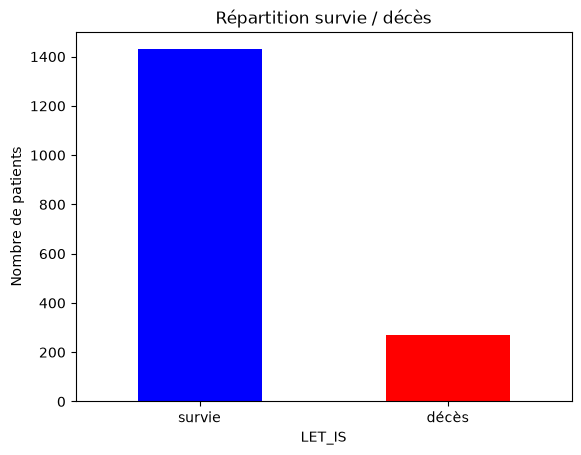

In [6]:
y = df["LET_IS"]

# On binarise la variable letale : 0 = survie, 1 = décès

for i in range(len(y)): 
    if y.iloc[i] > 0: 
        y.iloc[i] = 1

print("Répartition de la variable LET_IS")
print(y.value_counts().rename({0: "survie", 1: "décès"}))
print("Proportion de décès :", f"{y.mean():.1%}")

y.value_counts().rename({0: "survie", 1: "décès"}).plot(kind="bar", color=["blue", "red"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

**À retenir** : les classes sont **déséquilibrées** (les décès sont une minorité). L'*accuracy* ne suffira donc pas : un modèle qui prédit toujours « survie » aurait un score élevé tout en étant inutile. On utilisera le recall.

L'objectif de notre modèle est de rater le moins de decès possible, nous allons donc porter une attention particulière au recall.

## 5. Quelles variables sont disponibles à quel moment ?

Les colonnes suivent l'ordre chronologique du dossier médical. Certaines ne sont connues que **plus tard** dans l'hospitalisation :

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements des urgences | `NA_KB`, `NOT_NA_KB`, `LID_KB`, `NITR_S` | à l'admission (équipe d'urgence) |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | idem |
| Anti-inflammatoires en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | idem |
| Autres traitements en soins intensifs | `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour (moment exact à vérifier) |


In [7]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».
COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True  # à décider en groupe

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

## 6. Construction de `X_admission` et `X_jour3`

- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour).
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

On garde des **DataFrames** (avec les noms de colonnes) et on ne les convertit pas en tableaux numpy : sans les noms, on ne peut plus interpréter les résultats (importance des variables, SHAP, arbre de décision).

In [8]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 95)
Colonnes retirées pour l'admission : 16


## 7. Exploration des données de `X_admission` et `X_jour3`

On cherche a donnée un type chacune des variables qui vont nous servir à entrainer le modèle. On distingue 3 types de variables : 
- `binaire` pour les variables binaire
- `ordinal` (on place le seuil ordinale à 10)
- `continue`

On affiche également le pourcentage manquant pour chaque colonne

In [9]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())

for t in ["binaire", "ordinale", "continue"]:
    print(f"\n=== Variables {t}s ===")
    display(resume_all[resume_all["type"] == t].drop(columns="type").head())
    

type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64

=== Variables binaires ===


,nb_modalites,min,max,moyenne,% manquants
SEX,2,0.0,1.0,0.626471,0.000000
IBS_NASL,2,0.0,1.0,0.375000,95.764706
SIM_GIPERT,2,0.0,1.0,0.033688,0.470588
nr_11,2,0.0,1.0,0.025015,1.235294
nr_01,2,0.0,1.0,0.002382,1.235294



=== Variables ordinales ===


,nb_modalites,min,max,moyenne,% manquants
INF_ANAM,4,0.0,3.0,0.554835,0.235294
STENOK_AN,7,0.0,6.0,2.316186,6.235294
FK_STENOK,5,0.0,4.0,1.205286,4.294118
IBS_POST,3,0.0,2.0,1.160703,3.000000
GB,4,0.0,3.0,1.393258,0.529412



=== Variables continues ===


,nb_modalites,min,max,moyenne,% manquants
AGE,62,26.0,92.0,61.856974,0.470588
S_AD_KBRIG,30,0.0,260.0,136.907051,63.294118
D_AD_KBRIG,21,0.0,190.0,81.394231,63.294118
S_AD_ORIT,32,0.0,260.0,134.588276,15.705882
D_AD_ORIT,20,0.0,190.0,82.749477,15.705882


On affiche ici le pourcentage de valeur manquant par patient (par ligne)

In [10]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)

resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)

display(resume_patient.head())

,% manquants
ID,
1,8.11
2,2.70
3,2.70
4,8.11
5,2.70


Étude des données decès / survivant

In [11]:
n_surv, n_deces = (y == 0).sum(), (y == 1).sum()
print(f"Survie : {n_surv} ({n_surv/len(y):.1%}) | Décès : {n_deces} ({n_deces/len(y):.1%})")
print(f"Ratio : 1 décès pour {n_surv/n_deces:.1f} survivants")

Survie : 1429 (84.1%) | Décès : 271 (15.9%)
Ratio : 1 décès pour 5.3 survivants


Cause de décès (sur la database avant la bianarisation de le colonnes "LET_IS")

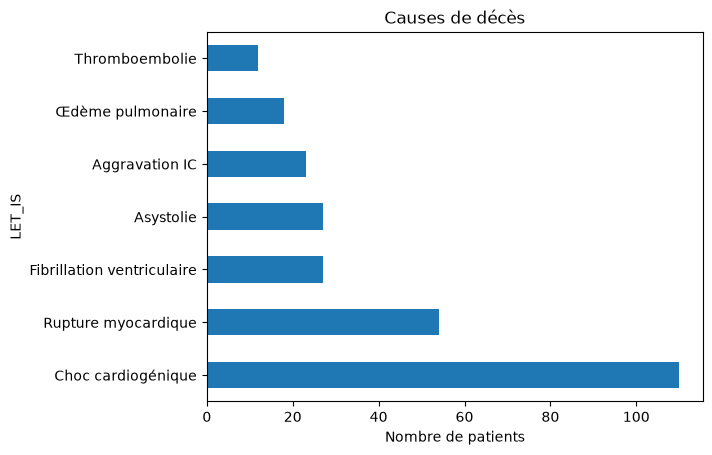

In [12]:
causes = {1: "Choc cardiogénique", 2: "Œdème pulmonaire", 3: "Rupture myocardique",
          4: "Aggravation IC", 5: "Thromboembolie", 6: "Asystolie", 7: "Fibrillation ventriculaire"}
df.loc[df["LET_IS"] > 0, "LET_IS"].map(causes).value_counts().plot(kind="barh")
plt.xlabel("Nombre de patients"); plt.title("Causes de décès"); plt.show()

## 8 - Séparation du jeu de données en train / test

In [13]:
from sklearn.model_selection import train_test_split

SEED = 42  # fixe le découpage : tout le groupe obtient les mêmes patients dans le train et le test

# 1. On sépare les PATIENTS (leurs identifiants), pas les tableaux.
#    Ainsi X_admission et X_jour3 ont exactement les mêmes patients de test.
idx_train, idx_test = train_test_split(
    y.index,
    test_size=0.2,    # 20 % des patients pour le test
    stratify=y,       # même proportion de décès dans le train et le test
    random_state=SEED,
)

# 2. On applique ce découpage aux deux scénarios et à la cible
X_adm_train, X_adm_test = X_admission.loc[idx_train], X_admission.loc[idx_test]
X_j3_train,  X_j3_test  = X_jour3.loc[idx_train],     X_jour3.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 3. Vérifications
print(f"Train : {len(idx_train)} patients, {y_train.sum()} décès ({y_train.mean():.1%})")
print(f"Test  : {len(idx_test)} patients, {y_test.sum()} décès ({y_test.mean():.1%})")

assert set(idx_train).isdisjoint(idx_test), "Des patients sont à la fois dans le train et le test"
assert X_adm_train.index.equals(X_j3_train.index) and X_adm_test.index.equals(X_j3_test.index)

Train : 1360 patients, 217 décès (16.0%)
Test  : 340 patients, 54 décès (15.9%)


## 9 - Études des données

KFK_BLOOD     99.7
S_AD_KBRIG    63.5
AST_BLOOD     16.9
ALT_BLOOD     16.8
S_AD_ORIT     16.2
D_AD_ORIT     16.2
ROE           12.4
L_BLOOD        7.6
AGE            0.4


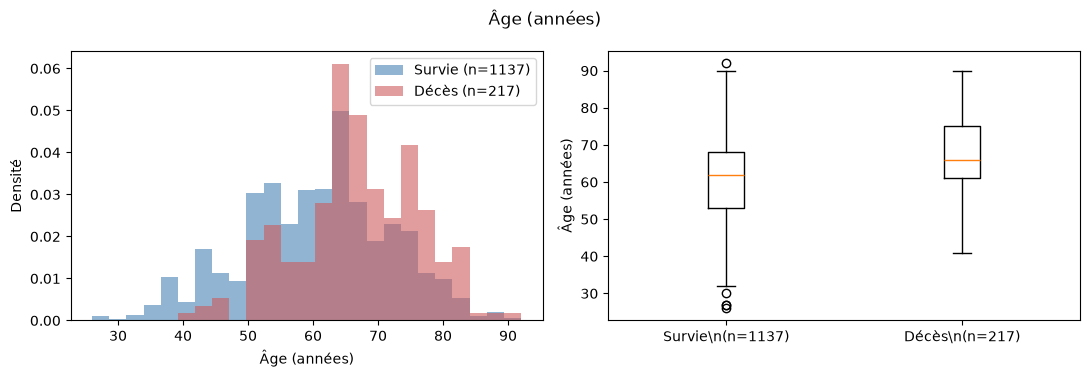

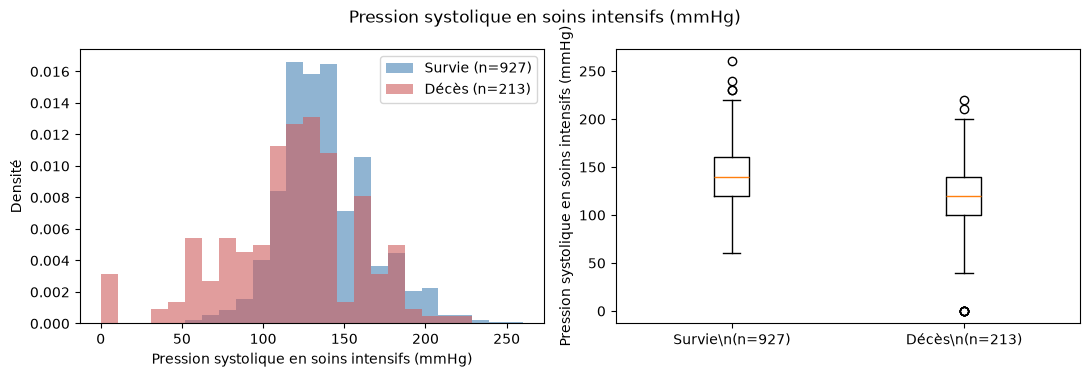

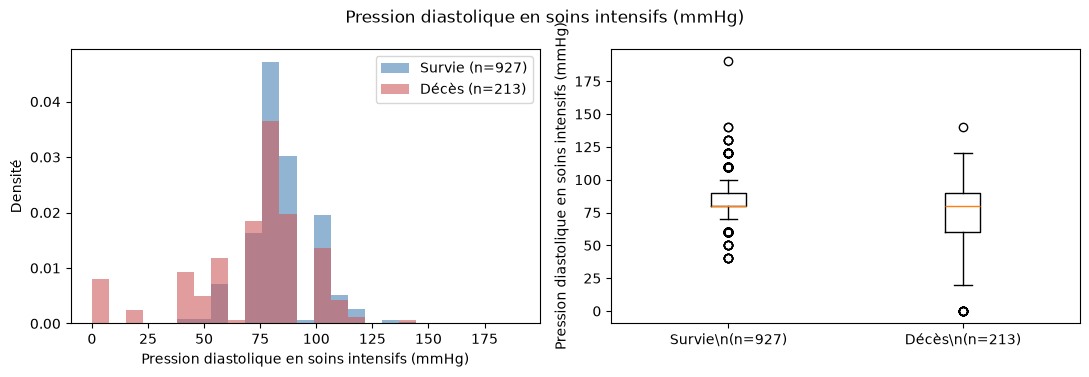

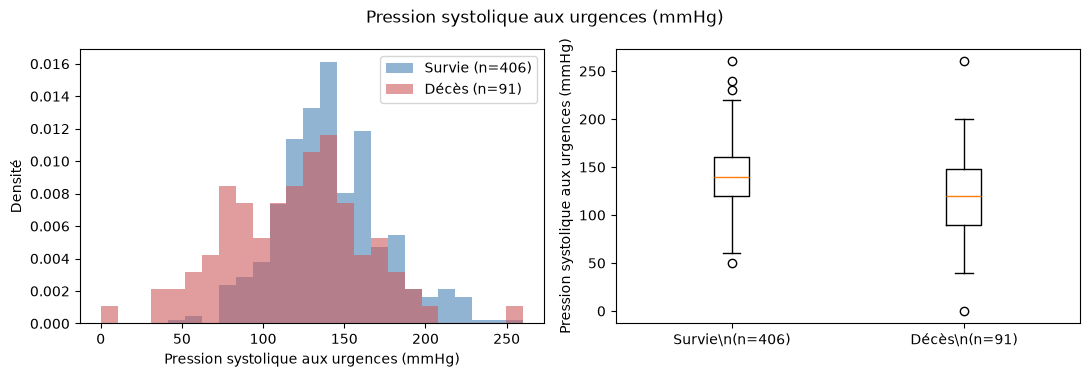

/Users/maximgasnier/miniforge3/envs/SDD/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


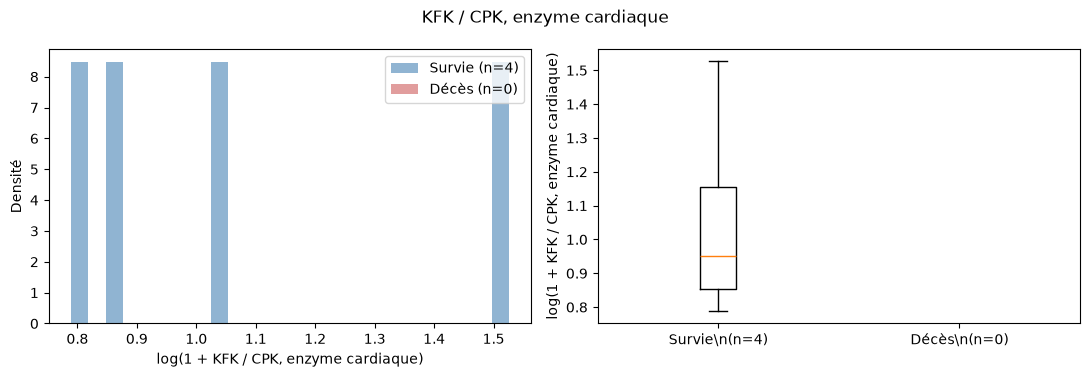

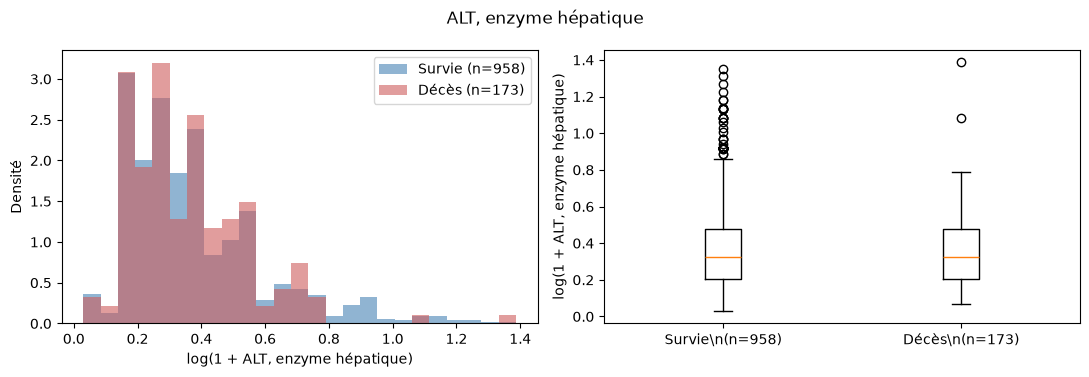

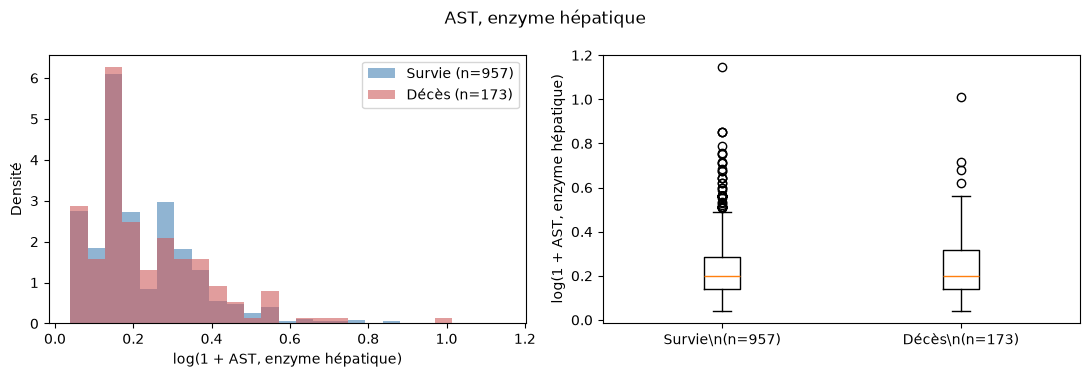

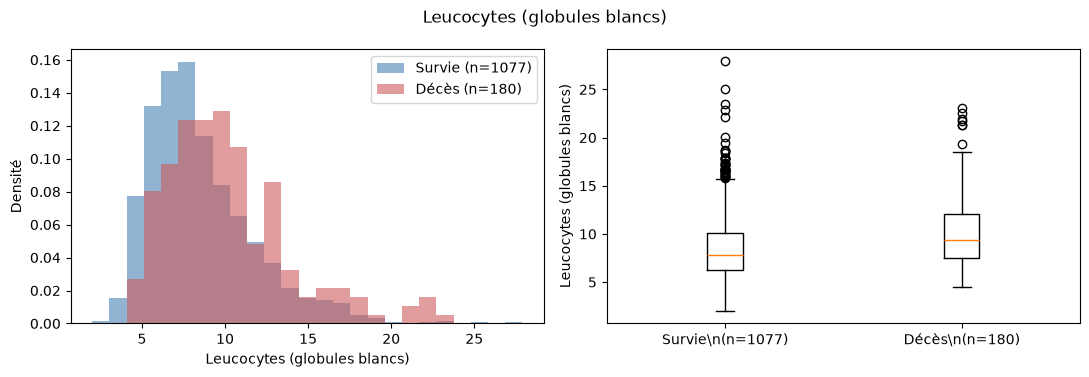

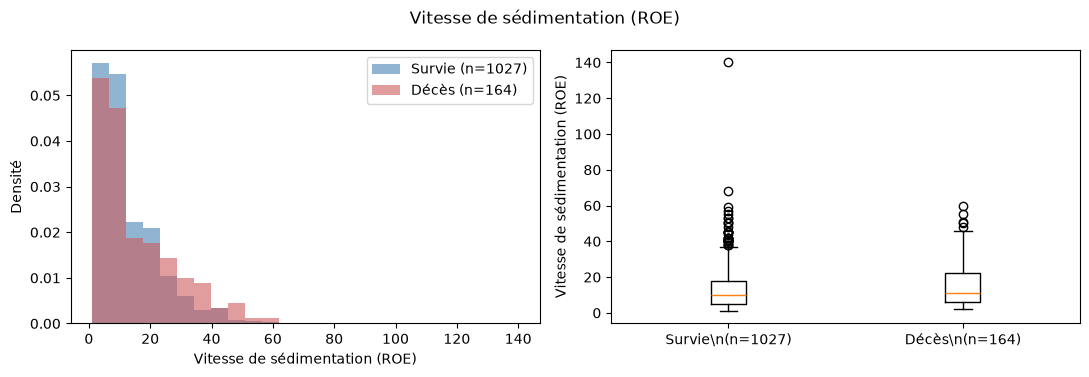

groupe            Décès  Survie
AGE        count  217.0  1137.0
           25%     61.0    53.0
           50%     66.0    62.0
           75%     75.0    68.0
S_AD_ORIT  count  213.0   927.0
           25%    100.0   120.0
           50%    120.0   140.0
           75%    140.0   160.0
D_AD_ORIT  count  213.0   927.0
           25%     60.0    80.0
           50%     80.0    80.0
           75%     90.0    90.0
S_AD_KBRIG count   91.0   406.0
           25%     90.0   120.0
           50%    120.0   140.0
           75%    147.5   160.0
KFK_BLOOD  count    0.0     4.0
           25%      NaN     1.3
           50%      NaN     1.6
           75%      NaN     2.2
ALT_BLOOD  count  173.0   958.0
           25%      0.2     0.2
           50%      0.4     0.4
           75%      0.6     0.6
AST_BLOOD  count  173.0   957.0
           25%      0.2     0.2
           50%      0.2     0.2
           75%      0.4     0.3
L_BLOOD    count  180.0  1077.0
           25%      7.5     6.3
        

In [16]:

# Tableau d'exploration : variables du jour 3 + groupe (survie / décès), train uniquement
exploration = X_j3_train.copy()
exploration["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

COULEURS = {"Survie": "steelblue", "Décès": "indianred"}

# colonne : (libellé, échelle logarithmique ?)
# Les unités sont à vérifier dans la description UCI.
VARIABLES = {
    "AGE":        ("Âge (années)", False),
    "S_AD_ORIT":  ("Pression systolique en soins intensifs (mmHg)", False),
    "D_AD_ORIT":  ("Pression diastolique en soins intensifs (mmHg)", False),
    "S_AD_KBRIG": ("Pression systolique aux urgences (mmHg)", False),
    "KFK_BLOOD":  ("KFK / CPK, enzyme cardiaque", True),
    "ALT_BLOOD":  ("ALT, enzyme hépatique", True),
    "AST_BLOOD":  ("AST, enzyme hépatique", True),
    "L_BLOOD":    ("Leucocytes (globules blancs)", False),
    "ROE":        ("Vitesse de sédimentation (ROE)", False),
}

def comparer(col, libelle, log=False):
    """Histogramme + boxplot de `col`, survivants contre décédés."""
    donnees = {g: exploration.loc[exploration["groupe"] == g, col].dropna()
               for g in ["Survie", "Décès"]}
    if log:  # variables très asymétriques : on passe à log(1 + x) pour y voir quelque chose
        donnees = {g: np.log1p(v) for g, v in donnees.items()}
    xlabel = f"log(1 + {libelle})" if log else libelle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

    # Histogramme : mêmes classes pour les deux groupes, et density=True car
    # les décès sont beaucoup moins nombreux (sinon leur barre serait invisible)
    tout = np.concatenate([v.values for v in donnees.values()])
    bins = np.histogram_bin_edges(tout, bins=25)
    for g, v in donnees.items():
        ax1.hist(v, bins=bins, density=True, alpha=0.6, color=COULEURS[g],
                 label=f"{g} (n={len(v)})")
    ax1.set_xlabel(xlabel); ax1.set_ylabel("Densité"); ax1.legend()

    # Boxplot avec l'effectif de chaque groupe
    ax2.boxplot([donnees["Survie"], donnees["Décès"]], showfliers=True)
    ax2.set_xticklabels([f"{g}\\n(n={len(donnees[g])})" for g in ["Survie", "Décès"]])
    ax2.set_ylabel(xlabel)

    fig.suptitle(libelle)
    plt.tight_layout()
    plt.show()

# 1. Regarder d'abord combien de valeurs manquantes (et donc combien de patients exploitables)
cols = list(VARIABLES)
print((exploration[cols].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

# 2. Un couple de graphiques par variable
for col, (libelle, log) in VARIABLES.items():
    comparer(col, libelle, log)

# 3. Tableau récapitulatif : médiane et quartiles par groupe
resume = exploration.groupby("groupe")[cols].describe().T.loc[(slice(None), ["count", "25%", "50%", "75%"]), :]
print(resume.round(1))

### Objectif

Nous cherchons à savoir si certaines *features* se comportent différemment chez les patients décédés et chez les survivants.

Pour chaque variable, nous traçons un histogramme (forme de la distribution) et un boxplot (comparaison des médianes et des dispersions). Quatre choix méthodologiques sont à noter :

- **Jeu d'entraînement uniquement** : les graphiques servent à prendre des décisions de preprocessing. Utiliser le jeu de test pour cela fausserait l'évaluation finale.
- **Histogrammes normalisés (densité)** : les décès sont beaucoup moins nombreux que les survies. Sans normalisation, la distribution des décès serait invisible.

- **Effectif affiché** sur chaque graphique : la comparaison n'a de sens que si chaque groupe contient assez de patients.

### Valeurs manquantes

Le pourcentage de valeurs manquantes varie fortement d'une variable à l'autre : [À REMPLIR : % pour AGE, pression, KFK, ALT/AST, leucocytes]. Une valeur manquante signifie souvent qu'un examen n'a pas été réalisé, et pas seulement qu'une saisie a été oubliée. Pour la variable [À REMPLIR : la plus incomplète], seuls [À REMPLIR : n] patients sont renseignés dans le train, dont [À REMPLIR : n] décédés : la comparaison est [possible / peu fiable / impossible], et nous [ne l'interprétons pas / l'interprétons avec prudence].

### Âge

Les patients décédés sont plus âgés que les survivants : l'âge médian est de 66 ans chez les décédés contre 62 ans chez les survivants. Les deux distributions se chevauchent  modérément.
L'Âge est une caractéristique interessante pour notre modèle.
Nous disposons également de cette valeur pour le cas des patients admis au urgence, nous retrouvons un écart à la médiane qui est similaire.

### Pression systolique

À l'entrée en soins intensifs, la pression systolique médiane est de 120 mmHg chez les survivants et de 100 mmHg chez les décédés. La différence est nette.
L'Âge est une caractéristique interessante pour notre modèle. 

### KFK (enzyme cardiaque)

La KFK (CPK) est une enzyme libérée par le muscle cardiaque lorsqu'il est lésé : elle est généralement associée à l'étendue de la nécrose. La variable est renseignée pour [À REMPLIR : n] patients seulement. [Si n est faible : « Cet effectif est insuffisant pour comparer les groupes ; nous ne tirons aucune conclusion et envisageons de supprimer cette colonne lors du preprocessing. » Sinon : décrivez l'écart entre les deux groupes]. [À REMPLIR : effet de l'échelle logarithmique].

### ALT et AST (enzymes hépatiques)

Ces enzymes reflètent l'état du foie, mais elles augmentent aussi lors de lésions cardiaques. Leurs distributions sont [très asymétriques], avec [À REMPLIR : n] valeurs très élevées. Chez les décédés, les valeurs sont [plus élevées / plus basses / comparables] : la médiane de l'ALT est de [À REMPLIR] contre [À REMPLIR] chez les survivants. ALT et AST évoluent probablement ensemble : nous le vérifierons dans la matrice de corrélation (section suivante). [À REMPLIR : interprétation clinique, ou question à poser à un médecin].

### Leucocytes

Les leucocytes (globules blancs) augmentent en cas de réaction inflammatoire. Le nombre médian est de [À REMPLIR] chez les survivants et de [À REMPLIR] chez les décédés. [À REMPLIR : écart, chevauchement, présence de valeurs extrêmes].

### Valeurs extrêmes

Les boxplots montrent des valeurs extrêmes pour [À REMPLIR : variables]. Nous ne les supprimons pas : chez des patients graves, ces valeurs peuvent être cliniquement réelles et précisément ce qui caractérise les cas à risque. [À REMPLIR : si une valeur est impossible, l'indiquer et préciser la décision prise].

### Synthèse

- Les variables qui semblent le mieux distinguer les deux groupes sont [À REMPLIR : 2 à 3 variables].
- Les variables qui semblent peu discriminantes sont [À REMPLIR].
- Aucune variable ne sépare **à elle seule** les survivants des décédés : les distributions se chevauchent toutes [beaucoup / en grande partie]. Un modèle de *machine learning* qui combine plusieurs *features* est donc justifié.
- Plusieurs variables sont très incomplètes ([À REMPLIR]) : cela guidera nos choix d'imputation et de suppression de colonnes dans la partie *preprocessing*.
- Les distributions asymétriques (enzymes) nous invitent à envisager une transformation logarithmique ou un modèle robuste à l'échelle (arbres, forêts).
- Une variable à créer lors du *feature engineering* : la pression pulsée (S_AD − D_AD).

### Questions pour un clinicien (pour la conclusion)

- [À REMPLIR : un résultat inattendu observé dans les graphiques]
- [À REMPLIR : une variable dont vous n'avez pas compris la signification médicale]
- Les valeurs manquantes de [À REMPLIR] correspondent-elles à un examen non prescrit ou à une saisie manquante ?